In [42]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = ("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [43]:
transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

In [44]:
train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True,
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False,
)

In [45]:
class ModelMNIST(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.network(x)

In [46]:
model = ModelMNIST().to(device)
print(model)

ModelMNIST(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): ReLU()
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [47]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [48]:
def fit(epochs=5):
    for epoch in range(epochs):
        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)

            predictions = model(X)
            loss = criterion(predictions, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * X.size(0)
            predicted_classes = predictions.argmax(dim=1)

            correct += (predicted_classes == y).sum().item()
            total += y.size(0)

        avg_loss = total_loss / total
        accuracy = correct / total

        print(
            f"Epoch: {epoch + 1}/epochs | ",
            f"Loss:{avg_loss} | ",
            f"Accuracy: {accuracy}",
        )

In [49]:
fit()

Epoch: 1/epochs |  Loss:0.32087469203472135 |  Accuracy: 0.9044666666666666
Epoch: 2/epochs |  Loss:0.11512519222100576 |  Accuracy: 0.9651833333333333
Epoch: 3/epochs |  Loss:0.07803663366039594 |  Accuracy: 0.97605
Epoch: 4/epochs |  Loss:0.05610234948682288 |  Accuracy: 0.9821166666666666
Epoch: 5/epochs |  Loss:0.04343716941786309 |  Accuracy: 0.98535


In [50]:
def evaluating():
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for X, y in test_loader:
            X, y = X.to(device), y.to(device)
            predictions = model(X)

            predicted_classes = predictions.argmax(dim=1)
            correct += (predicted_classes == y).sum().item()
            total += y.size(0)

    print("Accuracy:", correct / total)

In [51]:
evaluating()

Accuracy: 0.9789


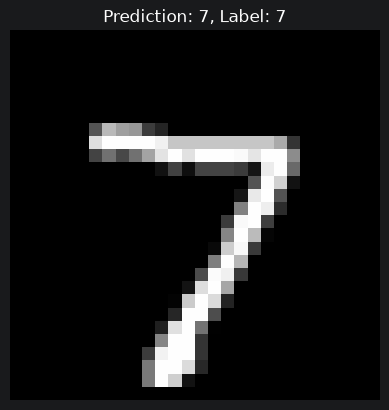

In [52]:
import matplotlib.pyplot as plt

image, label = test_data[0]
model.eval()

with torch.no_grad():
    prediction = model(image.unsqueeze(0).to(device))

predicted_digit = prediction.argmax(dim=1).item()

plt.imshow(image.squeeze().numpy(), cmap="gray")
plt.title(f"Prediction: {predicted_digit}, Label: {label}")
plt.axis("off")
plt.show()